# Домашнее задание 4. Деревья и ансамбли

## «Лес учится видеть»

Задача — предсказать класс каждого пикселя чёрно-белого изображения. **Balanced Accuracy (BA)** — средняя полнота по четырём классам. Ошибка на редком классе важна так же, как ошибка на частом.

Сначала я воспроизвожу базовый случайный лес и проверяю, что дают вертикальная разность яркостей, размер окна и число деревьев. Затем сравниваю наборы признаков для бустинга и уточняю границы текстур по вероятностям соседних пикселей. В конце ноутбук создаёт `submission.csv` для текущего размера `test.png`.

**Ограничения.** Итоговое предсказание делает один бустинг из 25 итераций, по четыре дерева на итерацию. Для обучения используется не более 20 000 уникальных пикселей из `train_0.png` и `train_1.png`. Результаты промежуточных лесов используются в экспериментах. Ноутбук работает с локальными данными и ограничивает обучение двумя потоками. На платформе лимиты — 10 минут, 4 ГБ памяти и 2 ядра.

**Как повторить запуск.** Распакуйте архив так, чтобы рядом с ноутбуком была папка `data/` с PNG. Поддерживается и исходная вложенность `trees-textures/data/`. Нужны Python, NumPy, SciPy, Pillow, scikit-learn, Matplotlib и threadpoolctl. Выполните **Restart Kernel and Run All**. При проверке платформа заменит `test.png` своим изображением. [Условие и данные соревнования](https://vsos.colloq.ru/k/trees-textures)

## 1. Загружаем данные

`load_png()` читает изображение как двумерный массив яркостей. Маски хранят номера цветов палитры. Поэтому маски открываются в исходном режиме и проверяются на допустимые метки от 0 до 3. Функция `boundary_mask()` отмечает пиксели, в окрестности которых шириной 7 пикселей есть хотя бы два истинных класса. Эту маску используем для разбора ошибок и отбора дополнительных обучающих строк.

In [1]:
import csv
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.ndimage import gaussian_filter, maximum_filter, minimum_filter, sobel, uniform_filter
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from threadpoolctl import threadpool_limits

DATA = Path("data")
if not DATA.is_dir() and Path("trees-textures/data").is_dir():
    DATA = Path("trees-textures/data")
SEED = 41
LABELS = np.arange(4, dtype=np.uint8)
NAMES = ["Горизонтальные штрихи", "Вертикальные штрихи", "Пятна", "Диагональные полосы"]
PALETTE = np.array([[49, 104, 174], [221, 151, 39], [52, 144, 104], [157, 91, 164]], dtype=np.uint8)


def load_png(name, *, mask=False):
    path = DATA / name
    if not path.is_file():
        raise FileNotFoundError(f"Нет {path}. Распакуйте архив так, чтобы data/ была рядом с ноутбуком.")
    with Image.open(path) as image:
        array = np.array(image if mask else image.convert("L"))
    if array.ndim != 2 or not array.size:
        raise ValueError(f"{path}: ожидается непустая двумерная PNG-матрица.")
    if mask and not np.isin(array, LABELS).all():
        raise ValueError(f"{path}: разрешены только классы 0, 1, 2 и 3.")
    return array.astype(np.uint8, copy=False)


def boundary_mask(mask, width=7):
    return maximum_filter(mask, size=width, mode="nearest") != minimum_filter(
        mask, size=width, mode="nearest",
    )

Обучающие изображения: [(256, 256), (256, 256)]
Валидация: (256, 256) · пикселей по классам: [12964, 16326, 18758, 17488]


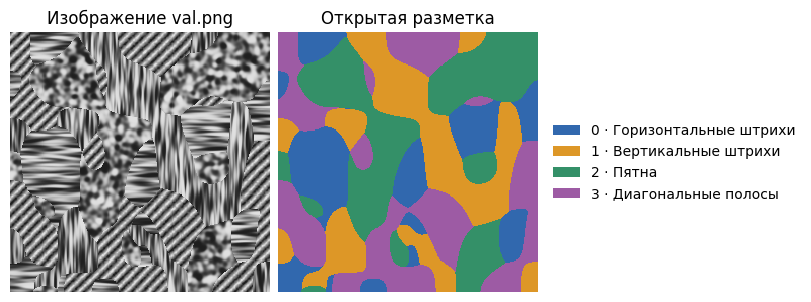

In [2]:
from matplotlib.patches import Patch

train_images = [load_png(f"train_{index}.png") for index in range(2)]
train_masks = [load_png(f"mask_{index}.png", mask=True) for index in range(2)]
val = load_png("val.png")
val_mask = load_png("val_mask.png", mask=True)
for image, mask in [*zip(train_images, train_masks), (val, val_mask)]:
    assert image.shape == mask.shape, "Размер маски должен совпадать с размером изображения."
    assert np.array_equal(np.unique(mask), LABELS), "В ожидаемой маске четыре класса."

print("Обучающие изображения:", [image.shape for image in train_images])
print("Валидация:", val.shape, "· пикселей по классам:", np.bincount(val_mask.ravel()).tolist())
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), constrained_layout=True)
axes[0].imshow(val, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[1].imshow(PALETTE[val_mask], interpolation="nearest")
for ax, title in zip(axes, ("Изображение val.png", "Открытая разметка")):
    ax.set_title(title)
    ax.axis("off")
axes[1].legend(
    handles=[Patch(facecolor=PALETTE[i] / 255, label=f"{i} · {name}") for i, name in enumerate(NAMES)],
    loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False,
)
plt.show()

## 2. Базовые признаки и вертикальная разность

`mean_window()` вычисляет среднее в квадратном окне с отражением у края изображения. `base_features()` повторяет исходные признаки яркости, локального стандартного отклонения и средней абсолютной разности с правым соседом. Добавляю среднюю разность с нижним соседом. В чистом горизонтальном штрихе яркости в одной строке похожи, а при движении вниз меняются. Для вертикального штриха характерно обратное.

Проверка создаёт два массива с одинаковым распределением яркости и разными направлениями штрихов. В центральном пикселе сравниваются значения обоих признаков.

In [3]:
def mean_window(array, window):
    return uniform_filter(array.astype(np.float32, copy=False), size=window, mode="reflect")


def base_features(gray, window, vertical=False):
    image = gray.astype(np.float32) / 255
    local_mean = mean_window(image, window)
    local_sd = np.sqrt(np.maximum(mean_window(image * image, window) - local_mean**2, 0))
    dx = np.abs(np.diff(image, axis=1, append=image[:, -1:]))
    fields = [image, local_sd, mean_window(dx, window)]
    if vertical:
        dy = np.abs(np.diff(image, axis=0, append=image[-1:, :]))
        fields.append(mean_window(dy, window))
    return fields

In [4]:
horizontal_stripes = np.tile(np.array([40, 200], dtype=np.uint8), (21, 11)).T
vertical_stripes = horizontal_stripes.T
for stripes, stronger, weaker in [(horizontal_stripes, 3, 2), (vertical_stripes, 2, 3)]:
    maps = base_features(stripes, 9, vertical=True)
    assert maps[stronger][10, 10] > maps[weaker][10, 10]
print("Проверка направления штрихов пройдена.")

Проверка направления штрихов пройдена.


## 3. Признаки направления и масштаба

- **Локальные градиенты.** `texture_features()` считает производные Собеля по двум осям. Средние от $g_x^2$, $g_y^2$ и $2g_xg_y$ на четырёх масштабах описывают силу и преимущественное направление градиента. У пятен устойчивое направление слабее, чем у полос.
- **Изменение яркости на разных расстояниях.** `offsets()` возвращает сдвинутые представления изображения. Для четырёх направлений сравниваем яркость с соседями на расстояниях 1, 2 и 4. Делим средние квадраты разностей на сумму по направлениям, чтобы учитывать и слабый, и сильный контраст.
- **Наклон диагонали.** Для пары диагональных направлений `direction_channels()` возвращает минимум и максимум, а смешанный градиент используется по модулю. При отражении две диагонали меняются местами, но значения этих признаков сохраняются. Это важно для переноса между обучающими изображениями с разным наклоном полос.

In [5]:
def local_gaussian(array, sigma):
    return gaussian_filter(array, sigma, mode="reflect", truncate=3.0)


def offsets(image, radius):
    padded = np.pad(image, radius, mode="symmetric")
    height, width = image.shape

    def shifted(dy, dx):
        return padded[radius + dy:radius + dy + height, radius + dx:radius + dx + width]

    return shifted


def direction_channels(arrays):
    horizontal, vertical, diagonal_a, diagonal_b = arrays
    return [horizontal, vertical, np.minimum(diagonal_a, diagonal_b),
            np.maximum(diagonal_a, diagonal_b)]


def texture_features(gray, window=9):
    image = gray.astype(np.float32) / 255
    shifted = offsets(image, 4)
    local_mean = mean_window(image, window)
    local_sd = np.sqrt(np.maximum(mean_window(image * image, window) - local_mean**2, 0))
    fields = [image, local_sd]
    for dy, dx in ((0, 1), (1, 0)):
        absolute_change = 0.5 * (abs(image - shifted(dy, dx)) + abs(image - shifted(-dy, -dx)))
        fields.append(mean_window(absolute_change, window))
    directions = [(0, 1), (1, 0), (1, 1), (1, -1)]

    # Компоненты тензора направлений. Нормировка учитывает локальный контраст.
    gx = sobel(image, axis=1, mode="reflect") / 8
    gy = sobel(image, axis=0, mode="reflect") / 8
    tensor = (gx * gx, gy * gy, 2 * gx * gy)
    for sigma in (0.85, 1.7, 3.2, 5.0):
        jxx, jyy, twice_jxy = [local_gaussian(component, sigma) for component in tensor]
        power = jxx + jyy
        axis_balance = (jyy - jxx) / (power + 1e-6)
        diagonal_balance = twice_jxy / (power + 1e-6)
        coherence = np.hypot(axis_balance, diagonal_balance)
        fields.extend([power, axis_balance, abs(diagonal_balance), coherence])

    # Энергия разностей по четырём направлениям и на нескольких расстояниях.
    for lag, scales in [(1, (0.8, 1.6, 3.2)), (2, (1.4, 3.0)), (4, (2.0, 4.0))]:
        energies, one_side, curvature = [], [], []
        for dy, dx in directions:
            plus = shifted(lag * dy, lag * dx)
            minus = shifted(-lag * dy, -lag * dx)
            delta_plus, delta_minus = image - plus, image - minus
            energies.append(0.5 * (delta_plus**2 + delta_minus**2))
            if lag in (1, 2):
                # Если один сосед за границей, второй может описывать ту же текстуру.
                one_side.append(local_gaussian(np.minimum(abs(delta_plus), abs(delta_minus)), 0.9))
                curvature.append(local_gaussian(abs(delta_plus + delta_minus), 1.2))
        if one_side:
            fields.extend(direction_channels(one_side))
            fields.extend(direction_channels(curvature))
        for sigma in scales:
            smoothed = [local_gaussian(energy, sigma) for energy in energies]
            total = sum(smoothed)
            fields.extend([total, *(energy / (total + 1e-6) for energy in direction_channels(smoothed))])

    # Смещённые окна добавляют контекст по разные стороны от пикселя.
    jxx, jyy, twice_jxy = tensor
    side_vectors = []
    for dy, dx in [(-2, 0), (2, 0), (0, -2), (0, 2)]:
        side_x, side_y, side_xy = [
            uniform_filter(component, size=5, origin=(dy, dx), mode="reflect")
            for component in (jxx, jyy, twice_jxy)
        ]
        power = side_x + side_y + 1e-6
        side_vectors.append(((side_y - side_x) / power, abs(side_xy) / power))
    for component in (0, 1):
        values = [vector[component] for vector in side_vectors]
        fields.extend([np.minimum.reduce(values), np.maximum.reduce(values)])

    return fields

### Признаки у границы

`line_features()` смотрит вдоль короткого отрезка по обе стороны пикселя. По каждой стороне оценивается, насколько менялась яркость и насколько движение было плавным. Сохраняются меньшая и большая оценки. На стыке одна сторона может пересечь другую текстуру, тогда меньшая оценка сохраняет сведения о непрерывности штриха. `feature_cube()` объединяет карты в массив `(высота, ширина, признаки)`.

Проверка ниже отражает реальный фрагмент и сверяет карты признаков после обратного отражения. Допуск нужен для округлений при фильтрации в `float32`.

In [6]:
def line_features(image):
    shifted = offsets(image, 4)
    direction_scores = []
    for dy, dx in ((0, 1), (1, 0), (1, 1), (1, -1)):
        changes, curvatures = [], []
        for sign in (-1, 1):
            neighbors = [shifted(sign * step * dy, sign * step * dx) for step in (1, 2, 3, 4)]
            changes.append(sum(abs(image - neighbor) / step
                               for step, neighbor in enumerate(neighbors, start=1)) / 4)
            first, second, third, _ = neighbors
            near_curve = abs(image - 2 * first + second)
            far_curve = abs(first - 2 * second + third)
            curvatures.append(0.6 * near_curve + 0.4 * far_curve)
        direction_scores.append([np.minimum(*changes), np.minimum(*curvatures),
                                 np.maximum(*changes), np.maximum(*curvatures)])

    fields = []
    for values in zip(*direction_scores):
        fields.extend(direction_channels(values))
    for values in list(zip(*direction_scores))[:2]:
        for sigma in (0.9, 2.0):
            average = [local_gaussian(term, sigma) for term in values]
            normalizer = sum(average) + 1e-5
            fields.extend(term / normalizer for term in direction_channels(average))
    return fields




def feature_cube(image, recipe, window=9):
    if recipe in ("multiscale", "full"):
        fields = texture_features(image, window)
        if recipe == "full":
            fields += line_features(fields[0])
    elif recipe in ("baseline", "vertical"):
        fields = base_features(image, window, vertical=recipe == "vertical")
    else:
        raise ValueError(f"Неизвестный набор признаков: {recipe}")
    return np.stack(fields, axis=-1).astype(np.float32, copy=False)

In [7]:
sample = val[21:74, 19:86]
original_features = feature_cube(sample, "full")
reflected_features = feature_cube(sample[:, ::-1], "full")[:, ::-1]
assert original_features.shape[:2] == sample.shape
assert np.isfinite(original_features).all()
np.testing.assert_allclose(original_features, reflected_features, atol=2e-5, rtol=2e-5)
print(f"Размерность итоговых признаков: {original_features.shape[-1]}. Проверка отражения пройдена.")

Размерность итоговых признаков: 107. Проверка отражения пройдена.


## 4. Фиксируем обучающие пиксели

`pixel_ids()` сначала повторяет стартовую выборку из 8 192 пикселей на изображение с seed 41. Для итоговой модели добавляем пиксели из оставшихся до 10 000 на изображение. При доборе немного повышаем шанс выбрать редкий класс или пиксель на стыке. Это даёт больше примеров переходных участков. Все варианты работают с одной и той же группой из максимум 20 000 уникальных пикселей. `training_rows()` берёт признаки и метку в одних и тех же координатах.

In [8]:
def pixel_ids(masks):
    # Точная стартовая выборка. Дополнительные пиксели берём из её дополнения.
    rng = np.random.default_rng(SEED)
    baseline = [rng.choice(mask.size, min(mask.size, 8192), replace=False) for mask in masks]
    rng = np.random.default_rng(SEED + 1)
    expanded = []
    for mask, ids in zip(masks, baseline):
        missing = min(mask.size, 10_000) - len(ids)
        if not missing:
            expanded.append(ids)
            continue
        available = np.ones(mask.size, dtype=bool)
        available[ids] = False
        candidates = np.flatnonzero(available)
        counts = np.bincount(mask.ravel(), minlength=len(LABELS))
        class_weight = 1 / np.sqrt(np.maximum(counts, 1))
        weights = class_weight[mask.ravel()[candidates]]
        weights *= np.where(boundary_mask(mask).ravel()[candidates], 2.0, 1.0)
        extra = rng.choice(candidates, missing, replace=False, p=weights / weights.sum())
        expanded.append(np.concatenate([ids, extra]))
    assert sum(len(ids) for ids in expanded) <= 20_000
    assert all(np.unique(ids).size == len(ids) for ids in expanded)
    return baseline, expanded


def training_rows(images, masks, ids_per_image, recipe, window=9):
    rows, labels = [], []
    for image, mask, ids in zip(images, masks, ids_per_image):
        maps = feature_cube(image, recipe, window)
        rows.append(maps.reshape(image.size, -1)[ids])
        labels.append(mask.ravel()[ids])
    X, y = np.concatenate(rows), np.concatenate(labels)
    assert np.isfinite(X).all() and np.array_equal(np.unique(y), LABELS)
    return X, y


def class_weights(labels):
    counts = np.bincount(labels, minlength=len(LABELS))
    return np.sqrt(counts.mean() / counts)[labels]



baseline_ids, final_ids = pixel_ids(train_masks)
print("Базовая выборка:", [len(ids) for ids in baseline_ids])
print("Расширенная выборка:", [len(ids) for ids in final_ids])
for base, full in zip(baseline_ids, final_ids):
    np.testing.assert_array_equal(full[:len(base)], base)

Базовая выборка: [8192, 8192]
Расширенная выборка: [10000, 10000]


## 5. Обучаем модели и восстанавливаем карту

`fit_forest()` повторяет настройки из базового ноутбука. `fit_boosting()` обучает гистограммный градиентный бустинг. В многоклассовом бустинге каждая итерация строит четыре дерева. `tree_count()` берёт фактическое число итераций из обученной модели. Веса бустинга немного повышают вклад примеров более редких классов.

`predict_probabilities()` предсказывает вероятности блоками. Каждый блок получает поля из соседних пикселей с запасом в 24 пикселя. После расчёта признаков сохраняется центральная область блока. Такой запас покрывает радиус фильтров, чтобы сетка блоков не влияла на границы текстур. `decode()` выбирает класс с максимальной вероятностью.

In [9]:
def fit_forest(X, y, trees):
    assert 1 <= trees <= 100
    model = RandomForestClassifier(
        n_estimators=trees, min_samples_leaf=3, max_features=1.0, random_state=SEED, n_jobs=2,
    )
    with threadpool_limits(limits=2):
        model.fit(X, y)
    return model


def fit_boosting(X, y):
    assert len(X) == len(y) <= 20_000
    model = HistGradientBoostingClassifier(
        max_iter=25, learning_rate=0.23, max_leaf_nodes=47, min_samples_leaf=22,
        l2_regularization=2.0, early_stopping=False, random_state=SEED,
    )
    with threadpool_limits(limits=2):
        model.fit(X, y, sample_weight=class_weights(y))
    assert tree_count(model) == 25 * len(LABELS) <= 100
    return model


def tree_count(model):
    if isinstance(model, RandomForestClassifier):
        return len(model.estimators_)
    return model.n_iter_ * model.n_trees_per_iteration_


def predict_probabilities(model, image, recipe, window=9, *, tile_size=256):
    # Запас покрывает радиус локальных фильтров, включая окна 21×21.
    halo = 24
    height, width = image.shape
    probabilities = np.empty((height, width, len(LABELS)), dtype=np.float32)
    assert np.array_equal(model.classes_, LABELS)
    with threadpool_limits(limits=2):
        for top in range(0, height, tile_size):
            bottom = min(top + tile_size, height)
            y0, y1 = max(0, top - halo), min(height, bottom + halo)
            for left in range(0, width, tile_size):
                right = min(left + tile_size, width)
                x0, x1 = max(0, left - halo), min(width, right + halo)
                block = feature_cube(image[y0:y1, x0:x1], recipe, window)
                central = block[top - y0:bottom - y0, left - x0:right - x0]
                central = central.reshape(-1, block.shape[-1])
                scores = model.predict_proba(central)
                probabilities[top:bottom, left:right] = scores.reshape(bottom - top, right - left, -1)
    return probabilities


def decode(probabilities):
    return np.argmax(probabilities, axis=-1).astype(np.uint8)

## 6. Сравнение с базовым лесом

`evaluate()` считает Balanced Accuracy и полноту каждого класса, а также долю ошибок на стыках и внутри областей. Доля ошибок измерена по числу пикселей каждой области. `error_panel()` выделяет неверные классы красным. Сначала сравниваем леса из десяти деревьев при окне 9×9 и на точно тех же пикселях. Меняется только наличие вертикальной разности.

In [10]:
def evaluate(truth, prediction):
    matrix = confusion_matrix(truth.ravel(), prediction.ravel(), labels=LABELS)
    recalls = matrix.diagonal() / matrix.sum(axis=1)
    balanced = balanced_accuracy_score(truth.ravel(), prediction.ravel())
    np.testing.assert_allclose(balanced, recalls.mean())
    border = boundary_mask(truth)
    errors = prediction != truth
    return {
        "ba": balanced,
        "border_error": errors[border].mean(),
        "interior_error": errors[~border].mean(),
        "recall": recalls,
    }


def print_metrics(title, stats):
    print(f"{title:<39} BA {stats['ba']:.4f}   "
          f"стык {stats['border_error']:6.2%}   внутри {stats['interior_error']:6.2%}")


def error_panel(image, truth, prediction):
    dimmed = (image * 0.4 + 30).astype(np.uint8)
    panel = np.repeat(dimmed[..., None], 3, axis=2)
    panel[truth != prediction] = [218, 50, 55]
    return panel


def forest_prediction(recipe, window, trees):
    X, y = training_rows(train_images, train_masks, baseline_ids, recipe, window)
    model = fit_forest(X, y, trees)
    return decode(predict_probabilities(model, val, recipe, window))


base_pred = forest_prediction("baseline", 9, 10)
vertical_pred = forest_prediction("vertical", 9, 10)
base_stats = evaluate(val_mask, base_pred)
vertical_stats = evaluate(val_mask, vertical_pred)
print_metrics("Базовый лес", base_stats)
print_metrics("Лес + вертикальная разность", vertical_stats)

Базовый лес                             BA 0.7646   стык 43.90%   внутри 15.16%
Лес + вертикальная разность             BA 0.8806   стык 30.85%   внутри  3.53%


### Размер окна при 10 деревьях

Меньшее окно захватывает меньше чужой текстуры у границы, но даёт менее устойчивую оценку направления. Большое окно должно быть полезнее внутри областей и может сглаживать границы. Проверяю оба предположения для окон 3×3, 9×9 и 21×21. На всех трёх картах красные пиксели обозначают ошибки.

Окно 3×3                                BA 0.7929   стык 30.82%   внутри 17.49%
Окно 9×9                                BA 0.8806   стык 30.85%   внутри  3.53%
Окно 21×21                              BA 0.8364   стык 42.80%   внутри  4.78%
Минимум ошибок на стыках: 3


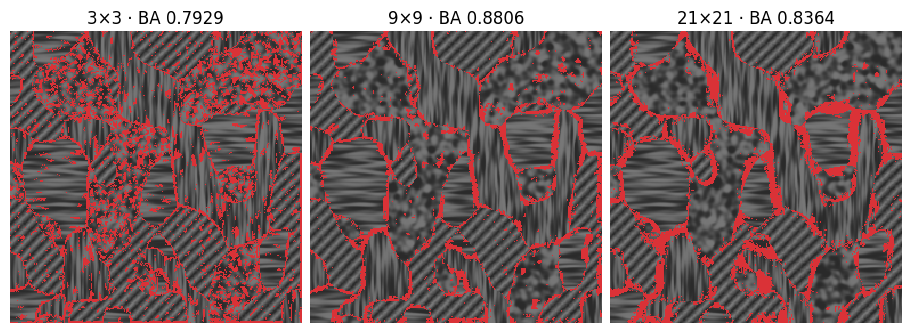

In [11]:
windows = {3: forest_prediction("vertical", 3, 10), 9: vertical_pred,
           21: forest_prediction("vertical", 21, 10)}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.5), constrained_layout=True)
window_stats = {}
for ax, (width, pred) in zip(axes, windows.items()):
    stats = window_stats[width] = evaluate(val_mask, pred)
    print_metrics(f"Окно {width}×{width}", stats)
    ax.imshow(error_panel(val, val_mask, pred), interpolation="nearest")
    ax.set_title(f"{width}×{width} · BA {stats['ba']:.4f}")
    ax.axis("off")
print("Минимум ошибок на стыках:",
      min(window_stats, key=lambda width: window_stats[width]["border_error"]))
plt.show()

### Число деревьев при окне 9×9

Сравниваю 1, 10 и 100 деревьев при одном наборе признаков и одном обучающем подмножестве. Разность BA между соседними вариантами показывает, где добавление деревьев даёт больший прирост.

Число деревьев: 1                       BA 0.8392   стык 36.46%   внутри  7.72%
Число деревьев: 10                      BA 0.8806   стык 30.85%   внутри  3.53%
Число деревьев: 100                     BA 0.8844   стык 30.34%   внутри  3.19%
  1 →  10 деревьев: +0.0414 BA
 10 → 100 деревьев: +0.0038 BA


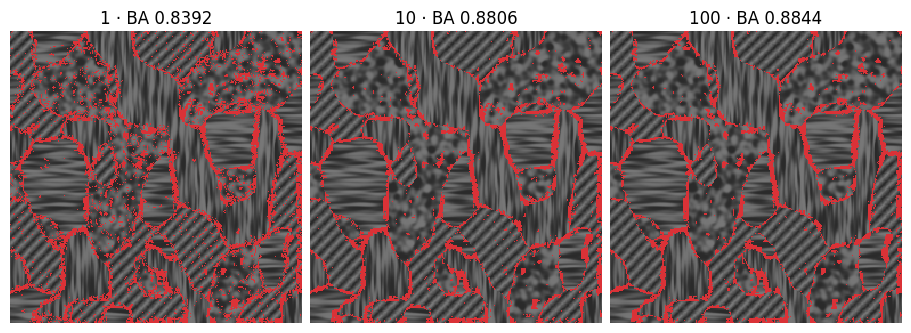

In [12]:
forests = {1: forest_prediction("vertical", 9, 1), 10: vertical_pred,
           100: forest_prediction("vertical", 9, 100)}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.5), constrained_layout=True)
forest_stats = {}
for ax, (count, pred) in zip(axes, forests.items()):
    stats = forest_stats[count] = evaluate(val_mask, pred)
    print_metrics(f"Число деревьев: {count}", stats)
    ax.imshow(error_panel(val, val_mask, pred), interpolation="nearest")
    ax.set_title(f"{count} · BA {stats['ba']:.4f}")
    ax.axis("off")
for before, after in [(1, 10), (10, 100)]:
    change = forest_stats[after]["ba"] - forest_stats[before]["ba"]
    print(f"{before:3} → {after:3} деревьев: {change:+.4f} BA")
plt.show()

Окно 3×3 дало чуть меньше ошибок на стыках, чем 9×9 (30,82% против 30,85%), но заметно больше ошибок внутри областей. Поэтому 9×9 дало наибольшую BA из трёх окон для этого леса. Увеличение леса с 1 до 10 деревьев улучшило BA на 0,0414, тогда как переход с 10 до 100 добавил 0,0038.

## 7. Уточнение границ по соседним пикселям

`refine_probabilities()` сначала слегка сглаживает карты вероятностей, чтобы убрать отдельные выбросы. Затем в четыре шага пересчитывает оценки, добавляя поддержку от восьми соседей. Сосед получает больший вес, когда он ближе и меньше отличается по яркости. Это позволяет учитывать согласованность текстуры в области и ослаблять перенос ошибочной метки через резкий перепад. После каждого шага оценки снова переводятся в вероятности.

Параметры уточнения зафиксированы после локальных экспериментов. При прогнозе используются только яркости входного изображения и вероятности бустинга.

In [13]:
def refine_probabilities(probabilities, gray, spatial_sigma=1.6, contrast=0.20):
    # Вес соседей зависит от расстояния и перепада яркости.
    image = gray.astype(np.float32) / 255
    height, width = image.shape
    neighbors = [(0, -1), (0, 1), (1, 0), (-1, 0), (1, 1), (-1, 1), (1, -1), (-1, -1)]
    posterior = local_gaussian(probabilities, (spatial_sigma, spatial_sigma, 0))
    unary = np.log(np.maximum(posterior, 1e-5))
    shifted = offsets(image, 1)
    weights = []
    for dy, dx in neighbors:
        diff = np.abs(image - shifted(dy, dx))
        weights.append(np.exp(-0.5 * (diff / contrast)**2) / np.hypot(dy, dx))
    for _ in range(4):
        padded = np.pad(posterior, ((1, 1), (1, 1), (0, 0)), mode="symmetric")
        scores = unary.copy()
        for (dy, dx), weight in zip(neighbors, weights):
            neighbor = padded[1 + dy:1 + dy + height, 1 + dx:1 + dx + width]
            scores += weight[..., None] * neighbor
        posterior = np.exp(scores - scores.max(axis=-1, keepdims=True))
        posterior /= posterior.sum(axis=-1, keepdims=True)
    return posterior

## 8. Что дало прирост на открытой валидации

Сравниваю два бустинга на одних и тех же пикселях. Первый получает признаки нескольких масштабов, второй дополнительно видит односторонние отрезки. Затем сравниваю способы преобразования вероятностей **одного и того же** полного бустинга. Это позволяет оценить, сколько прибавляют признаки стыка и сколько прибавляет уточнение границ.

Открытая валидация использовалась при выборе признаков и настроек. Полученные значения описывают эту проверку.

In [14]:
start = perf_counter()
X_multiscale, y_multiscale = training_rows(train_images, train_masks, final_ids, "multiscale")
multiscale_model = fit_boosting(X_multiscale, y_multiscale)
multiscale_prob = predict_probabilities(multiscale_model, val, "multiscale")

X_full, y_full = training_rows(train_images, train_masks, final_ids, "full")
np.testing.assert_array_equal(y_multiscale, y_full)
model = fit_boosting(X_full, y_full)
val_prob = predict_probabilities(model, val, "full")
gaussian_prob = local_gaussian(val_prob, (1.6, 1.6, 0))
refined_prob = refine_probabilities(val_prob, val)
np.testing.assert_allclose(refined_prob.sum(axis=-1), 1.0, atol=1e-6)

val_pred = decode(refined_prob)
comparisons = [
    ("Базовый лес", base_pred),
    ("Лес + вертикальная разность", vertical_pred),
    ("Бустинг, несколько масштабов", decode(multiscale_prob)),
    ("Бустинг + односторонние признаки", decode(val_prob)),
    ("Полный бустинг + сглаживание", decode(gaussian_prob)),
    ("Полный бустинг + уточнение", val_pred),
]
for name, pred in comparisons:
    print_metrics(name, evaluate(val_mask, pred))
final_stats = evaluate(val_mask, val_pred)
print(f"Прирост к базовому решению: {100 * (final_stats['ba'] - base_stats['ba']):+.2f} п. п.")
print(f"Построение и сравнение бустингов: {perf_counter() - start:.1f} с")

Базовый лес                             BA 0.7646   стык 43.90%   внутри 15.16%
Лес + вертикальная разность             BA 0.8806   стык 30.85%   внутри  3.53%
Бустинг, несколько масштабов            BA 0.9607   стык 11.93%   внутри  0.44%
Бустинг + односторонние признаки        BA 0.9806   стык  5.86%   внутри  0.36%
Полный бустинг + сглаживание            BA 0.9870   стык  4.23%   внутри  0.10%
Полный бустинг + уточнение              BA 0.9896   стык  3.40%   внутри  0.04%
Прирост к базовому решению: +22.51 п. п.
Построение и сравнение бустингов: 4.0 с


### Где остались ошибки

На первой строке видны входное изображение, истинная разметка, итоговый прогноз и его ошибки. График полноты показывает результат для каждого класса до и после изменений. Balanced Accuracy даёт всем четырём столбцам одинаковый вес.

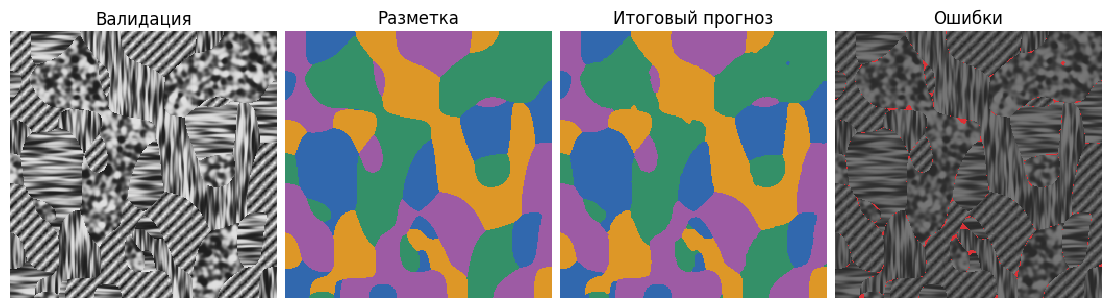

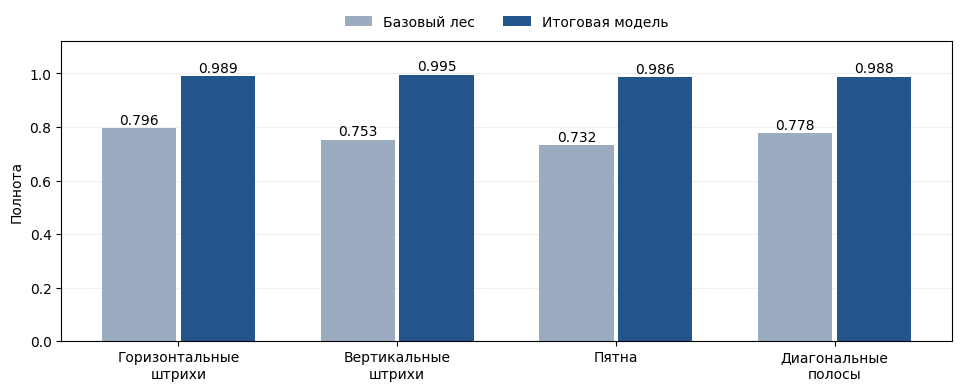

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3), constrained_layout=True)
for ax, title, panel in zip(
    axes, ("Валидация", "Разметка", "Итоговый прогноз", "Ошибки"),
    (val, PALETTE[val_mask], PALETTE[val_pred], error_panel(val, val_mask, val_pred)),
):
    ax.imshow(panel, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
positions = np.arange(len(LABELS))
for offset, stats, name, color in [(-0.18, base_stats, "Базовый лес", "#9BACC0"),
                                   (0.18, final_stats, "Итоговая модель", "#23558D")]:
    bars = ax.bar(positions + offset, stats["recall"], 0.34, label=name, color=color)
    for bar, value in zip(bars, stats["recall"]):
        ax.annotate(f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 3), textcoords="offset points", ha="center")
ax.set_xticks(positions)
ax.set_xticklabels(["Горизонтальные\nштрихи", "Вертикальные\nштрихи", "Пятна",
                          "Диагональные\nполосы"])
ax.set_ylabel("Полнота")
ax.set_ylim(0, 1.12)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

### Проверяем перенос между изображениями

Дополнительная проверка выполняется в обе стороны. Бустинг обучается на выбранных пикселях одного тренировочного изображения и проверяется на другом. Так соседние пиксели одного и того же рисунка не попадают по разные стороны разделения. Для посылки по-прежнему используется модель, обученная на обоих изображениях.

In [16]:
split = len(final_ids[0])
slices = (slice(0, split), slice(split, None))
for fit_index, check_index in [(0, 1), (1, 0)]:
    fit_rows = slices[fit_index]
    single_model = fit_boosting(X_full[fit_rows], y_full[fit_rows])
    check_image = train_images[check_index]
    check_prob = predict_probabilities(single_model, check_image, "full")
    check_pred = decode(refine_probabilities(check_prob, check_image))
    print_metrics(
        f"train_{fit_index} → train_{check_index}",
        evaluate(train_masks[check_index], check_pred),
    )

train_0 → train_1                       BA 0.9863   стык  4.91%   внутри  0.05%


train_1 → train_0                       BA 0.9771   стык  6.67%   внутри  0.11%


## 9. Формируем и проверяем посылку

Сначала сравниваю предсказание на одном прямоугольном фрагменте при двух размерах блока. Затем записываю классы для `data/test.png` построчно, слева направо. Проверяю заголовок, число строк, допустимые классы и соответствие каждой строки исходной карте. Размер тестового изображения читается из PNG.

In [17]:
test_region = val[8:137, 15:190]
single_block = predict_probabilities(model, test_region, "full", tile_size=256)
multiple_blocks = predict_probabilities(model, test_region, "full", tile_size=71)
np.testing.assert_array_equal(decode(multiple_blocks), decode(single_block))

test = load_png("test.png")
test_prob = predict_probabilities(model, test, "full")
result = decode(refine_probabilities(test_prob, test))
assert result.shape == test.shape
assert np.isin(result, LABELS).all()
assert tree_count(model) <= 100
assert sum(len(ids) for ids in final_ids) <= 20_000

submission = Path("submission.csv")
flat = result.ravel(order="C")
with submission.open("w", encoding="utf-8", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["id", "label"])
    writer.writerows((pixel, int(label)) for pixel, label in enumerate(flat))

checked = 0
with submission.open(encoding="utf-8", newline="") as stream:
    rows = csv.reader(stream)
    assert next(rows) == ["id", "label"]
    for pixel, (index, label) in enumerate(rows):
        assert pixel < flat.size and int(index) == pixel
        assert int(label) == int(flat[pixel])
        checked += 1
assert checked == test.size
print(f"Итоговая модель: {tree_count(model)} деревьев, {len(y_full):,} уникальных обучающих пикселей.")
print(f"В {submission} проверено {checked:,} прогнозов для изображения {test.shape[0]}×{test.shape[1]}.")

Итоговая модель: 100 деревьев, 20,000 уникальных обучающих пикселей.
В submission.csv проверено 30,720 прогнозов для изображения 160×192.


## 10. Карточка участника

| Поле | Данные |
|---|---|
| Фамилия и имя | [Впишите фамилию и имя] |
| Учебная группа | [Впишите группу] |
| Точное имя / ник в лидерборде | [Скопируйте имя из лидерборда] |

### Пояснение к решению

В лесу из десяти деревьев вертикальная разность яркостей увеличила Balanced Accuracy с **0,7646** до **0,8806**. Итоговый бустинг сравнивает изменения яркости по нескольким направлениям и масштабам. Признаки из коротких односторонних отрезков увеличили BA бустинга с **0,9607** до **0,9806**. Согласование вероятностей соседних пикселей с учётом перепада яркости дало **0,9896** на приложенной открытой валидации. Доля ошибок на стыках снизилась с **43,90%** у базового леса до **3,40%** у итоговой модели.

### Сдача и оценивание

1. Загрузить исполняемый ноутбук на платформу и проверить, что посылка принята. [Страница посылок](https://vsos.colloq.ru/k/trees-textures/submissions)
2. Заполнить карточку и сдать в LMS файл `HW4_Фамилия_Имя.ipynb` до **21 ноября 2026, 23:00 МСК**.

Итоговая оценка зависит от приватной метрики $s$. Шкала задания $10\min(1,\max(0,(s-0{,}9395)/0{,}0362))$ даёт 10 баллов при $s\geq0{,}9757$. [Лидерборд соревнования](https://vsos.colloq.ru/k/trees-textures/leaderboard)